# Explainable Student Dropout Risk Prediction Using Machine Learning

**Revised, block-wise notebook**

This version defines the prediction point as **after the first semester** and excludes columns containing `2nd sem` / `second semester` from model inputs. It uses cross-validation on the training split for model selection, keeps the test split for final evaluation, applies RandomOverSampler only inside training folds, and includes SHAP and LIME explanations.

**Before running:** upload the UCI dataset CSV when prompted. The dataset is expected to contain a `Target` column with `Dropout`, `Enrolled`, and `Graduate` labels. Run the notebook from top to bottom in a fresh Google Colab runtime. Results will depend on the dataset and package versions.

## Block 0 — Install dependencies


In [2]:
%pip -q install imbalanced-learn xgboost shap lime

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 8.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


## Block 1 — Import libraries and define labels


In [3]:
import warnings
warnings.filterwarnings("default")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.pipeline import Pipeline as SklearnPipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, classification_report,
    confusion_matrix, roc_auc_score, make_scorer
)
from sklearn.inspection import permutation_importance

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import RandomOverSampler
from xgboost import XGBClassifier

RANDOM_STATE = 42
CLASS_NAMES = ["Dropout", "Enrolled", "Graduate"]
TARGET_MAPPING = {"Dropout": 0, "Enrolled": 1, "Graduate": 2}
LABEL_MAPPING = {v: k for k, v in TARGET_MAPPING.items()}

print("Libraries imported successfully.")

Libraries imported successfully.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## Block 2 — Load the dataset


In [4]:
# Google Colab: upload the UCI dataset CSV.
# The expected file is usually named "data.csv" and uses semicolons as separators.
try:
    from google.colab import files
    uploaded = files.upload()
    if not uploaded:
        raise ValueError("No file was uploaded.")
    csv_path = next(iter(uploaded.keys()))
except ImportError:
    # For Jupyter/local execution, place the CSV beside this notebook or update this path.
    csv_path = "data.csv"

if "csv_path" not in globals():
    csv_path = "data.csv"

try:
    df = pd.read_csv(csv_path, sep=";")
    # Fallback for a comma-separated file if semicolon parsing produced one column.
    if df.shape[1] == 1:
        df = pd.read_csv(csv_path)
except FileNotFoundError as exc:
    raise FileNotFoundError(
        "Dataset not found. Upload the UCI dataset CSV in Colab or place it at data.csv."
    ) from exc

# Remove tabs/spaces accidentally included in column names.
df.columns = df.columns.astype(str).str.replace(chr(9), "", regex=False).str.strip()

if "Target" not in df.columns:
    raise ValueError(
        "The dataset must contain a 'Target' column. Check the CSV file and separator."
    )

print("Dataset loaded:", df.shape)
display(df.head())

Saving data.csv to data.csv
Dataset loaded: (4424, 37)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


## Block 3 — Inspect the dataset


In [5]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("Data type"))

print("\nMissing values per column:")
display(df.isna().sum().sort_values(ascending=False).to_frame("Missing values").head(15))

print("\nDuplicate rows:", int(df.duplicated().sum()))
print("\nTarget values:")
print(df["Target"].value_counts(dropna=False))

Rows: 4424
Columns: 37

Column names:
['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', 'Unemployment rate', 'Inflation

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Data type
Marital status,int64
Application mode,int64
Application order,int64
Course,int64
Daytime/evening attendance,int64
Previous qualification,int64
Previous qualification (grade),float64
Nacionality,int64
Mother's qualification,int64
Father's qualification,int64



Missing values per column:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Missing values
Marital status,0
Application mode,0
Application order,0
Course,0
Daytime/evening attendance,0
Previous qualification,0
Previous qualification (grade),0
Nacionality,0
Mother's qualification,0
Father's qualification,0



Duplicate rows: 0

Target values:
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## Block 4 — Visualize target distribution


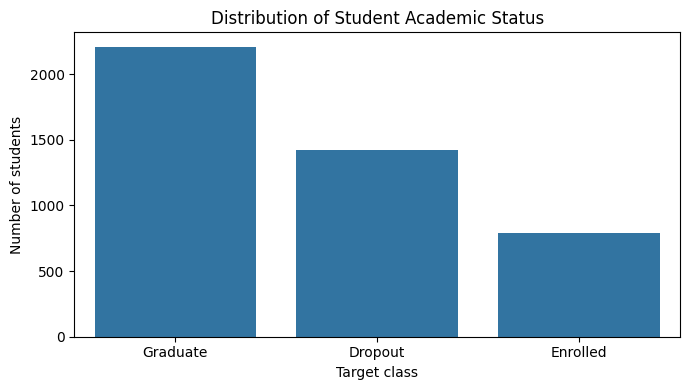

Class percentages:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Percentage
Target,
Graduate,49.93
Dropout,32.12
Enrolled,17.95


In [6]:
target_counts = df["Target"].value_counts(dropna=False)

plt.figure(figsize=(7, 4))
sns.barplot(x=target_counts.index.astype(str), y=target_counts.values)
plt.title("Distribution of Student Academic Status")
plt.xlabel("Target class")
plt.ylabel("Number of students")
plt.tight_layout()
plt.show()

print("Class percentages:")
display((df["Target"].value_counts(normalize=True) * 100).round(2).to_frame("Percentage"))

## Block 5 — Define the early-warning prediction stage and prepare features


In [7]:
# Define the prediction point: after the first semester.
# To avoid using future information, remove second-semester performance features.
if df["Target"].isna().any():
    df = df.dropna(subset=["Target"]).copy()

X_all = df.drop(columns=["Target"]).copy()
y_raw = df["Target"].astype(str).str.strip()

future_columns = [
    col for col in X_all.columns
    if "2nd sem" in col.lower() or "second semester" in col.lower()
]
X = X_all.drop(columns=future_columns).copy()

# Convert features to numeric and replace infinite values with missing values.
X = X.apply(pd.to_numeric, errors="coerce")
X = X.replace([np.inf, -np.inf], np.nan)

unknown_targets = sorted(set(y_raw.unique()) - set(TARGET_MAPPING))
if unknown_targets:
    raise ValueError(f"Unexpected target labels found: {unknown_targets}")

y = y_raw.map(TARGET_MAPPING).astype(int)

print("Prediction stage: after the first semester")
print("Excluded future-information columns:", future_columns if future_columns else "None found")
print("Features retained:", X.shape[1])
print("X shape:", X.shape, "| y shape:", y.shape)
print("Target mapping:", TARGET_MAPPING)

Prediction stage: after the first semester
Excluded future-information columns: ['Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)']
Features retained: 30
X shape: (4424, 30) | y shape: (4424,)
Target mapping: {'Dropout': 0, 'Enrolled': 1, 'Graduate': 2}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## Block 6 — Check data quality


In [8]:
# Inspect whether any feature is completely missing.
all_missing = X.columns[X.isna().all()].tolist()
if all_missing:
    print("Dropping completely empty feature columns:", all_missing)
    X = X.drop(columns=all_missing)

print("Missing values remaining before imputation:", int(X.isna().sum().sum()))
print("Duplicate records in the feature table:", int(X.duplicated().sum()))

# Keep all features numeric; median imputation will be fitted on training folds only.
print("Final feature count:", X.shape[1])
display(X.head())

Missing values remaining before imputation: 0
Duplicate records in the feature table: 0
Final feature count: 30


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Unemployment rate,Inflation rate,GDP
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0,0.000000,0,10.8,1.4,1.74
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,0,6,6,6,14.000000,0,13.9,-0.3,0.79
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,0,6,0,0,0.000000,0,10.8,1.4,1.74
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,0,6,8,6,13.428571,0,9.4,-0.8,-3.12
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,0,6,9,5,12.333333,0,13.9,-0.3,0.79


## Block 7 — Create the train-test split


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("\nTraining class counts:")
display(y_train.map(LABEL_MAPPING).value_counts().to_frame("Count"))
print("\nTest class counts:")
display(y_test.map(LABEL_MAPPING).value_counts().to_frame("Count"))

Training rows: 3539
Test rows: 885

Training class counts:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Count
Target,
Graduate,1767
Dropout,1137
Enrolled,635



Test class counts:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Count
Target,
Graduate,442
Dropout,284
Enrolled,159


## Block 8 — Inspect class imbalance and explain the balancing strategy


In [10]:
print("Training class distribution before balancing:")
display(y_train.map(LABEL_MAPPING).value_counts().to_frame("Count"))

print("\nBalancing strategy:")
print(
    "RandomOverSampler will duplicate minority-class training rows. "
    "Unlike ordinary SMOTE, it will not create fractional values for encoded categorical features."
)
print("The sampler will run inside each cross-validation training fold and will never touch the test set.")

Training class distribution before balancing:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Count
Target,
Graduate,1767
Dropout,1137
Enrolled,635



Balancing strategy:
RandomOverSampler will duplicate minority-class training rows. Unlike ordinary SMOTE, it will not create fractional values for encoded categorical features.
The sampler will run inside each cross-validation training fold and will never touch the test set.


## Block 9 — Set the number of selected features


In [11]:
k_features = min(20, X_train.shape[1])
print(f"SelectKBest will retain {k_features} features in each training fold.")
print("Feature selection is part of the model pipeline to reduce leakage during cross-validation.")

SelectKBest will retain 20 features in each training fold.
Feature selection is part of the model pipeline to reduce leakage during cross-validation.


## Block 10 — Define classifiers and preprocessing pipelines


In [12]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=3000, class_weight=None, random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=None, random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=250, random_state=RANDOM_STATE, n_jobs=1
    ),
    "SVM": SVC(
        probability=True, random_state=RANDOM_STATE
    ),
    "XGBoost": XGBClassifier(
        n_estimators=250,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="multi:softprob",
        num_class=3,
        eval_metric="mlogloss",
        random_state=RANDOM_STATE,
        n_jobs=1
    )
}

def make_model_pipeline(estimator):
    return Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("sampler", RandomOverSampler(random_state=RANDOM_STATE)),
        ("selector", SelectKBest(score_func=mutual_info_classif, k=k_features)),
        ("classifier", estimator)
    ])

pipelines = {name: make_model_pipeline(model) for name, model in models.items()}
print("Pipelines prepared:", ", ".join(pipelines.keys()))

Pipelines prepared: Logistic Regression, Decision Tree, Random Forest, SVM, XGBoost


## Block 11 — Compare models using cross-validation


In [13]:
# Model selection uses cross-validation on the training set only.
# The held-out test set remains untouched until the final evaluation.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "precision_weighted": "precision_weighted",
    "recall_weighted": "recall_weighted",
    "f1_weighted": "f1_weighted",
    "f1_macro": "f1_macro",
    "balanced_accuracy": "balanced_accuracy"
}

cv_rows = []
for name, pipeline in pipelines.items():
    print(f"Cross-validating: {name}")
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        error_score="raise",
        return_train_score=False
    )
    cv_rows.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Weighted Precision": scores["test_precision_weighted"].mean(),
        "Weighted Recall": scores["test_recall_weighted"].mean(),
        "Weighted F1": scores["test_f1_weighted"].mean(),
        "Macro F1": scores["test_f1_macro"].mean(),
        "Balanced Accuracy": scores["test_balanced_accuracy"].mean(),
        "CV Macro F1 Std": scores["test_f1_macro"].std()
    })

cv_results = pd.DataFrame(cv_rows).sort_values("Macro F1", ascending=False).reset_index(drop=True)
display(cv_results.round(4))

Cross-validating: Logistic Regression


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Cross-validating: Decision Tree


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Cross-validating: Random Forest


...

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Cross-validating: XGBoost


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,Model,Accuracy,Weighted Precision,Weighted Recall,Weighted F1,Macro F1,Balanced Accuracy,CV Macro F1 Std
0,XGBoost,0.7361,0.7553,0.7361,0.7425,0.6907,0.6943,0.0173
1,Random Forest,0.7395,0.7304,0.7395,0.7320,0.6692,0.6624,0.0203
2,Logistic Regression,0.7118,0.7448,0.7118,0.7228,0.6678,0.6731,0.0150
3,SVM,0.7056,0.7373,0.7056,0.7154,0.6602,0.6637,0.0219
4,Decision Tree,0.6394,0.6419,0.6394,0.6404,0.5769,0.5767,0.0219


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## Block 12 — Visualize cross-validation results


<Figure size 1200x600 with 0 Axes>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


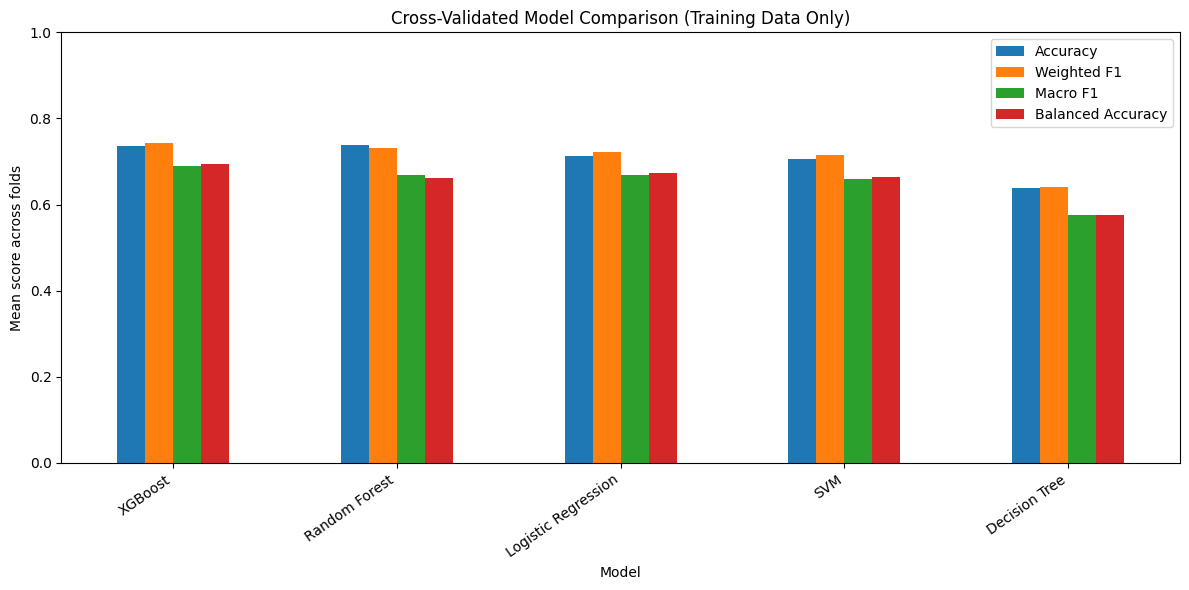

Primary model-selection metric: Macro F1.
Macro F1 gives equal weight to Dropout, Enrolled, and Graduate.


In [14]:
plt.figure(figsize=(12, 6))
cv_results.set_index("Model")[["Accuracy", "Weighted F1", "Macro F1", "Balanced Accuracy"]].plot(
    kind="bar", figsize=(12, 6)
)
plt.title("Cross-Validated Model Comparison (Training Data Only)")
plt.ylabel("Mean score across folds")
plt.ylim(0, 1)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

print("Primary model-selection metric: Macro F1.")
print("Macro F1 gives equal weight to Dropout, Enrolled, and Graduate.")

## Block 13 — Select and fit the best model


In [15]:
best_model_name = cv_results.loc[cv_results["Macro F1"].idxmax(), "Model"]
best_model = pipelines[best_model_name]

print("Selected model based on cross-validated Macro F1:", best_model_name)
best_model.fit(X_train, y_train)
print("Final pipeline fitted on the full training set.")

Selected model based on cross-validated Macro F1: XGBoost


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Final pipeline fitted on the full training set.


## Block 14 — Evaluate on the untouched test set


In [16]:
# Final evaluation: the test set is used only after model selection is complete.
y_pred = best_model.predict(X_test)
y_probability = best_model.predict_proba(X_test)

final_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Weighted Precision": precision_score(y_test, y_pred, average="weighted", zero_division=0),
    "Weighted Recall": recall_score(y_test, y_pred, average="weighted", zero_division=0),
    "Weighted F1": f1_score(y_test, y_pred, average="weighted", zero_division=0),
    "Macro F1": f1_score(y_test, y_pred, average="macro", zero_division=0),
    "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred)
}

try:
    final_metrics["Weighted ROC-AUC (OVR)"] = roc_auc_score(
        y_test, y_probability, labels=[0, 1, 2], multi_class="ovr", average="weighted"
    )
except ValueError as exc:
    print("ROC-AUC could not be calculated:", exc)

print("Final held-out test metrics:")
display(pd.DataFrame([final_metrics]).round(4))

Final held-out test metrics:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Accuracy,Weighted Precision,Weighted Recall,Weighted F1,Macro F1,Balanced Accuracy,Weighted ROC-AUC (OVR)
0,0.7107,0.746,0.7107,0.7227,0.67,0.6794,0.8814


## Block 15 — Plot the confusion matrix


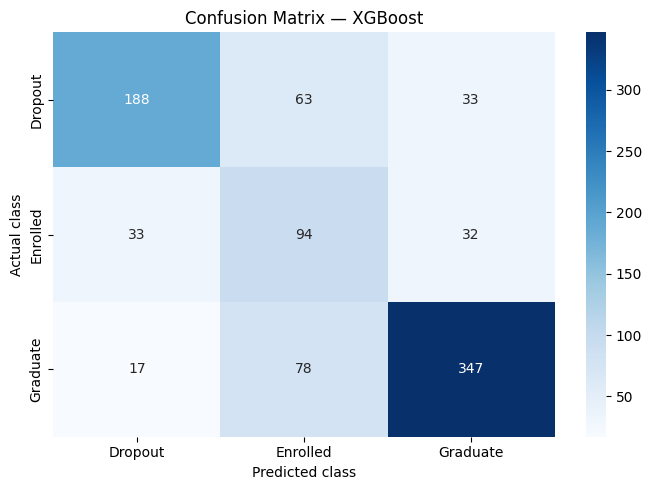

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [17]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES
)
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

## Block 16 — Print the classification report


In [18]:
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1, 2],
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
))

per_class_recall = recall_score(y_test, y_pred, labels=[0, 1, 2], average=None, zero_division=0)
print("\nClass-wise recall:")
for class_name, score in zip(CLASS_NAMES, per_class_recall):
    print(f"{class_name}: {score:.3f}")

print("\nInterpretation reminder: inspect Enrolled-class recall carefully; overall accuracy can hide weak performance on a minority class.")

              precision    recall  f1-score   support

     Dropout     0.7899    0.6620    0.7203       284
    Enrolled     0.4000    0.5912    0.4772       159
    Graduate     0.8422    0.7851    0.8126       442

    accuracy                         0.7107       885
   macro avg     0.6774    0.6794    0.6700       885
weighted avg     0.7460    0.7107    0.7227       885


Class-wise recall:
Dropout: 0.662
Enrolled: 0.591
Graduate: 0.785

Interpretation reminder: inspect Enrolled-class recall carefully; overall accuracy can hide weak performance on a minority class.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## Block 17 — Calculate per-class ROC-AUC


In [19]:
# Per-class ROC-AUC (one-vs-rest), when each class is present in the test set.
from sklearn.preprocessing import label_binarize

y_test_binary = label_binarize(y_test, classes=[0, 1, 2])
per_class_auc = {}
for idx, class_name in enumerate(CLASS_NAMES):
    try:
        per_class_auc[class_name] = roc_auc_score(y_test_binary[:, idx], y_probability[:, idx])
    except ValueError:
        per_class_auc[class_name] = np.nan

display(pd.DataFrame({
    "Class": list(per_class_auc.keys()),
    "ROC-AUC (OVR)": list(per_class_auc.values())
}).round(4))

print("ROC-AUC measures class separation; it is not the same as accuracy.")

,Class,ROC-AUC (OVR)
0,Dropout,0.8913
1,Enrolled,0.7859
2,Graduate,0.9093


ROC-AUC measures class separation; it is not the same as accuracy.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## Block 18 — Display selected features and feature importance


Selected features used by the final model:
- Application mode
- Course
- Previous qualification
- Previous qualification (grade)
- Mother's qualification
- Father's qualification
- Mother's occupation
- Father's occupation
- Admission grade
- Debtor
- Tuition fees up to date
- Gender
- Scholarship holder
- Age at enrollment
- Curricular units 1st sem (enrolled)
- Curricular units 1st sem (evaluations)
- Curricular units 1st sem (approved)
- Curricular units 1st sem (grade)
- Inflation rate
- GDP


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Feature,Importance
16,Curricular units 1st sem (approved),0.1737
10,Tuition fees up to date,0.1373
12,Scholarship holder,0.0636
17,Curricular units 1st sem (grade),0.0606
15,Curricular units 1st sem (evaluations),0.0537
14,Curricular units 1st sem (enrolled),0.0527
13,Age at enrollment,0.0456
9,Debtor,0.0449
6,Mother's occupation,0.0416
11,Gender,0.0382


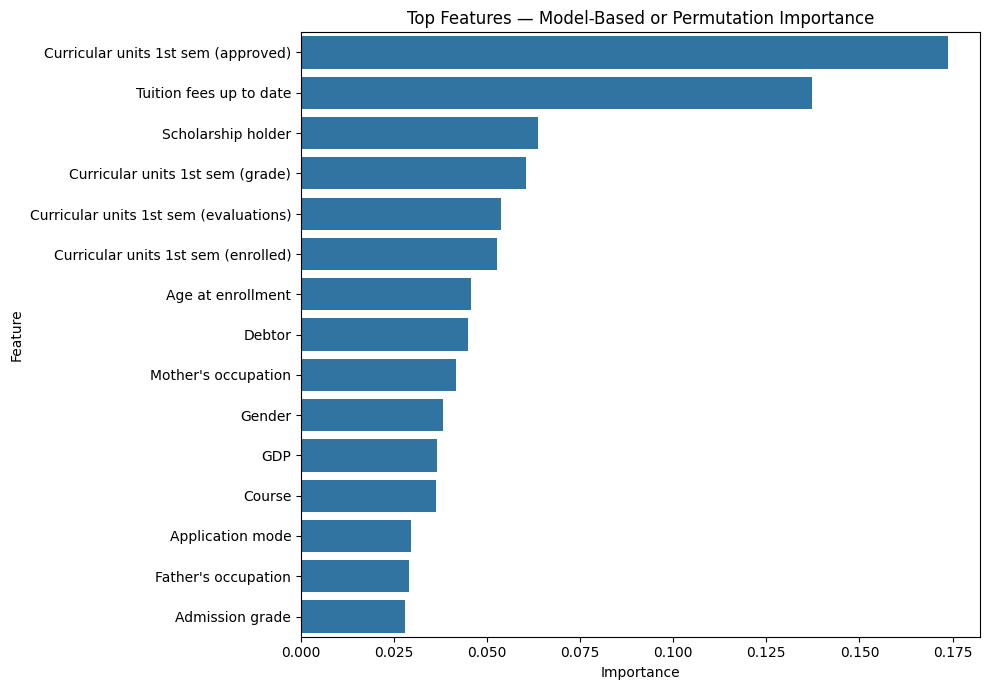

Feature importance indicates model association, not causation.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [20]:
# Extract the final selected feature names from the fitted pipeline.
selector = best_model.named_steps["selector"]
selected_features = X_train.columns[selector.get_support()].tolist()
classifier = best_model.named_steps["classifier"]

print("Selected features used by the final model:")
for feature in selected_features:
    print("-", feature)

if hasattr(classifier, "feature_importances_"):
    importances = classifier.feature_importances_
    importance_df = pd.DataFrame({"Feature": selected_features, "Importance": importances})
else:
    # For linear/SVM models, use permutation importance on the held-out set for interpretation.
    perm = permutation_importance(
        best_model, X_test, y_test, scoring="f1_macro",
        n_repeats=3, random_state=RANDOM_STATE, n_jobs=1
    )
    importance_df = pd.DataFrame({
        "Feature": X_test.columns,
        "Importance": perm.importances_mean
    })

importance_df = importance_df.sort_values("Importance", ascending=False)
display(importance_df.head(15).round(4))

plt.figure(figsize=(10, 7))
sns.barplot(data=importance_df.head(15), x="Importance", y="Feature")
plt.title("Top Features — Model-Based or Permutation Importance")
plt.tight_layout()
plt.show()

print("Feature importance indicates model association, not causation.")

## Block 19 — Calculate SHAP values


In [21]:
# SHAP explanations using the complete fitted pipeline and raw input features.
# Permutation SHAP is model-agnostic and works with this preprocessing pipeline.
import shap

feature_names = X_train.columns.tolist()
background = X_train.sample(n=min(20, len(X_train)), random_state=RANDOM_STATE)
shap_rows = X_test.sample(n=min(20, len(X_test)), random_state=RANDOM_STATE)

def predict_proba_for_shap(data):
    data_frame = pd.DataFrame(data, columns=feature_names)
    return best_model.predict_proba(data_frame)

shap_explainer = shap.Explainer(
    predict_proba_for_shap,
    background,
    algorithm="permutation"
)
max_evals = 2 * len(feature_names) + 1
shap_values = shap_explainer(shap_rows, max_evals=max_evals)

print("SHAP values calculated.")
print("SHAP value array shape:", np.asarray(shap_values.values).shape)

SHAP values calculated.
SHAP value array shape: (20, 30, 3)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## Block 20 — Plot global and individual SHAP explanations


Global SHAP summary for the Dropout class:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


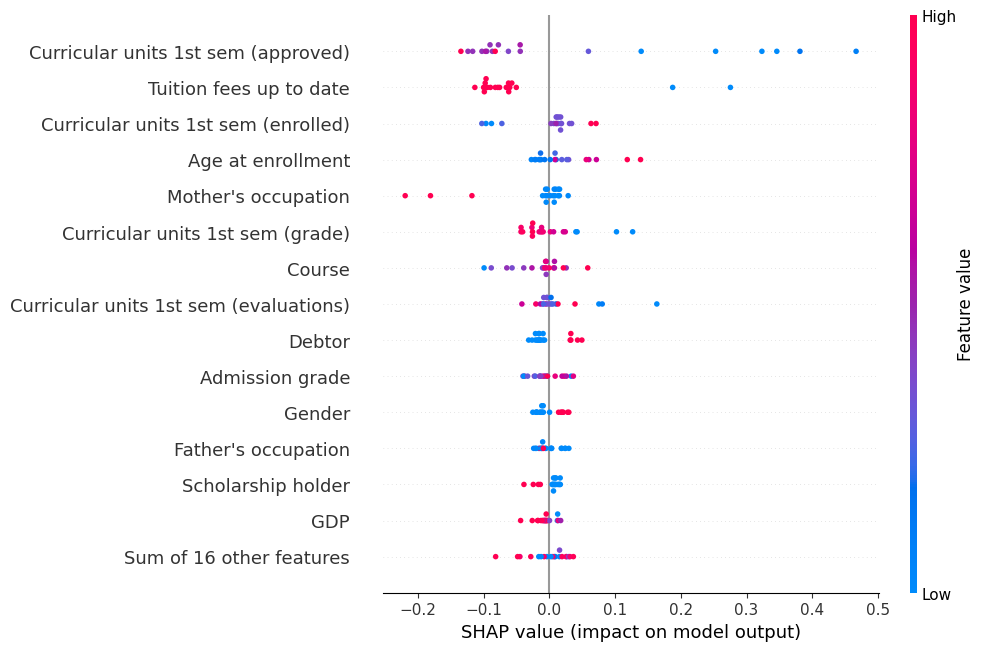

Individual SHAP explanation for the first explained student:


/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  parse = parser.parseString(pattern)
/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:89: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  parser.resetCache()
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2010: PyparsingDeprecationWarning: 'oneOf' deprecated - use 'one_of'
  p.space          = oneOf(self._space_widths)("space")
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2012: PyparsingDeprecationWarning: 'oneOf' deprecated - use 'one_of'
  p.style_literal  = oneOf(
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2020: PyparsingDeprecationWarning: 'leaveWhitespace' deprecated - use 'leave_whitespace'
  )("sym").leaveWhitespace()
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2024: PyparsingDeprecationWarning: 'oneO

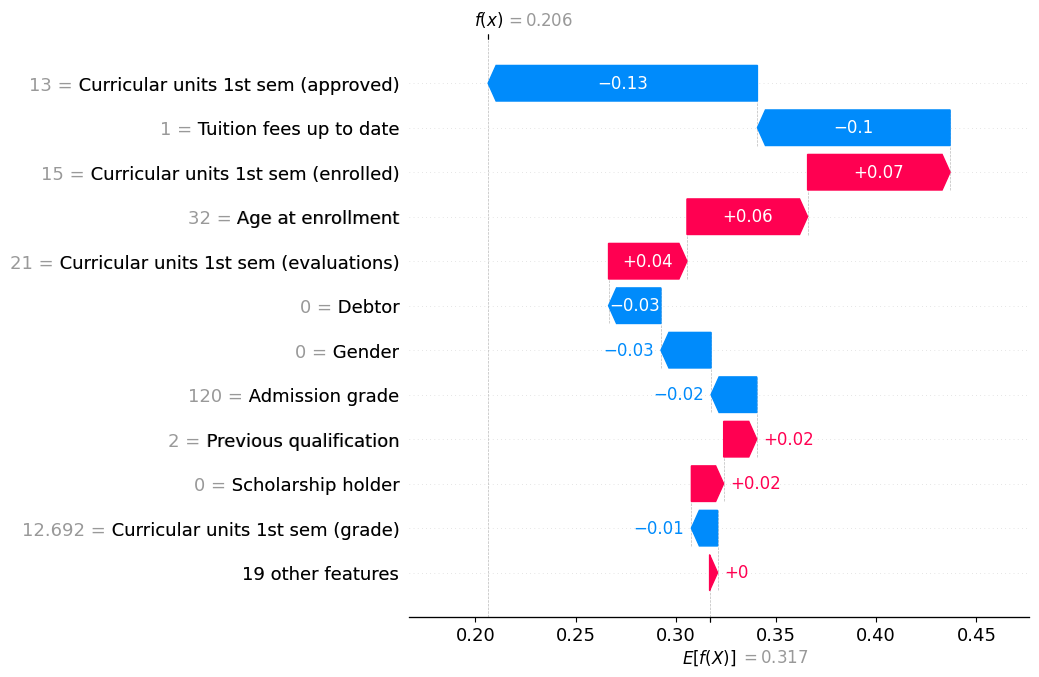

In [22]:
# Global SHAP plot and one individual explanation for the Dropout class.
shap_array = np.asarray(shap_values.values)
base_array = np.asarray(shap_values.base_values)
class_index = TARGET_MAPPING["Dropout"]

if shap_array.ndim == 3:
    class_shap_values = shap_array[:, :, class_index]
    if base_array.ndim == 2:
        class_base_values = base_array[:, class_index]
    else:
        class_base_values = base_array
elif shap_array.ndim == 2:
    class_shap_values = shap_array
    class_base_values = base_array
else:
    raise ValueError(f"Unexpected SHAP value shape: {shap_array.shape}")

dropout_explanation = shap.Explanation(
    values=class_shap_values,
    base_values=class_base_values,
    data=shap_rows.to_numpy(),
    feature_names=feature_names
)

print("Global SHAP summary for the Dropout class:")
shap.plots.beeswarm(dropout_explanation, max_display=15)

print("Individual SHAP explanation for the first explained student:")
shap.plots.waterfall(dropout_explanation[0], max_display=12)

## Block 21 — Generate an individual LIME explanation


Actual status: Graduate
Predicted status: Graduate


/usr/local/lib/python3.13/dist-packages/lime/explanation.py:251: ResourceWarning: unclosed file <_io.TextIOWrapper name='/usr/local/lib/python3.13/dist-packages/lime/bundle.js' mode='r' encoding='utf8'>
  encoding="utf8").read()
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


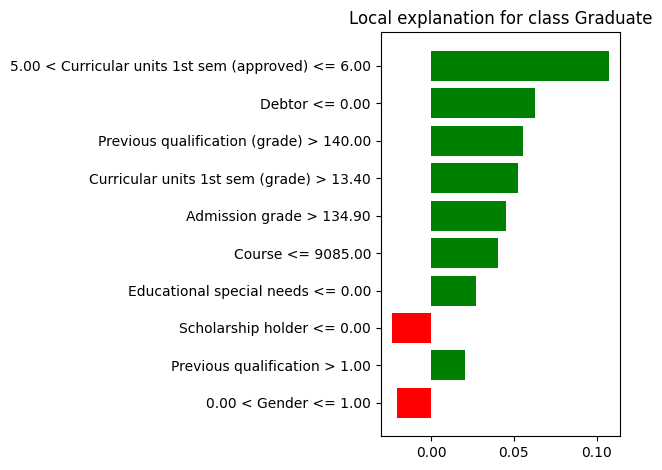

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [23]:
# LIME explanation for one individual student.
from lime.lime_tabular import LimeTabularExplainer

lime_explainer = LimeTabularExplainer(
    training_data=X_train.to_numpy(dtype=float),
    feature_names=feature_names,
    class_names=CLASS_NAMES,
    mode="classification",
    discretize_continuous=True,
    random_state=RANDOM_STATE
)

def predict_proba_for_lime(data):
    data_frame = pd.DataFrame(data, columns=feature_names)
    return best_model.predict_proba(data_frame)

lime_index = 0
lime_row = X_test.iloc[lime_index].to_numpy(dtype=float)
lime_exp = lime_explainer.explain_instance(
    lime_row,
    predict_proba_for_lime,
    labels=[0, 1, 2],
    num_features=min(10, len(feature_names))
)

print("Actual status:", LABEL_MAPPING[int(y_test.iloc[lime_index])])
print("Predicted status:", LABEL_MAPPING[int(y_pred[lime_index])])
lime_exp.show_in_notebook(show_table=True)
fig = lime_exp.as_pyplot_figure(label=int(y_pred[lime_index]))
plt.tight_layout()
plt.show()

## Block 22 — Demonstrate prediction on a held-out student


In [24]:
# Test an individual held-out student and show all class probabilities.
student_index = 0
student_row = X_test.iloc[[student_index]]
predicted_code = int(best_model.predict(student_row)[0])
probabilities = best_model.predict_proba(student_row)[0]

print("Actual status:", LABEL_MAPPING[int(y_test.iloc[student_index])])
print("Predicted status:", LABEL_MAPPING[predicted_code])
print("\nPredicted class probabilities:")
for class_code, probability in enumerate(probabilities):
    print(f"{LABEL_MAPPING[class_code]}: {probability * 100:.2f}%")

Actual status: Graduate
Predicted status: Graduate

Predicted class probabilities:
Dropout: 3.52%
Enrolled: 9.65%
Graduate: 86.83%


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## Block 23 — Create a reusable student prediction function


In [25]:
def predict_student(student_data):
    """Predict a student's status from a dict or pandas Series of eligible features."""
    student_df = pd.DataFrame([dict(student_data)])

    # Require every training feature and keep the same column order as training.
    missing = [col for col in feature_names if col not in student_df.columns]
    extra = [col for col in student_df.columns if col not in feature_names]
    if missing:
        raise ValueError(f"Missing required feature(s): {missing}")
    if extra:
        print("Ignoring extra feature(s):", extra)

    student_df = student_df.reindex(columns=feature_names)
    student_df = student_df.apply(pd.to_numeric, errors="coerce")

    prediction_code = int(best_model.predict(student_df)[0])
    probabilities = best_model.predict_proba(student_df)[0]

    result = {
        "predicted_status": LABEL_MAPPING[prediction_code],
        "probabilities": {
            LABEL_MAPPING[i]: round(float(probabilities[i]) * 100, 2)
            for i in range(len(CLASS_NAMES))
        }
    }

    print("\nSTUDENT STATUS PREDICTION")
    print("Predicted status:", result["predicted_status"])
    print("Class probabilities:")
    for label, probability in result["probabilities"].items():
        print(f"  {label}: {probability:.2f}%")

    return result

print("predict_student() is ready. Required feature count:", len(feature_names))

predict_student() is ready. Required feature count: 30


## Block 24 — Test the prediction function


In [26]:
# Demonstrate the prediction function with one real row from the test set.
# This is a demonstration example, not a guarantee of future student outcomes.
sample_student = X_test.iloc[0].to_dict()
sample_result = predict_student(sample_student)


STUDENT STATUS PREDICTION
Predicted status: Graduate
Class probabilities:
  Dropout: 3.52%
  Enrolled: 9.65%
  Graduate: 86.83%


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## Block 25 — Save the complete model bundle


In [27]:
# Save a complete bundle so preprocessing and feature order stay consistent.
import joblib

model_bundle = {
    "model": best_model,
    "model_name": best_model_name,
    "feature_names": feature_names,
    "target_mapping": TARGET_MAPPING,
    "label_mapping": LABEL_MAPPING,
    "prediction_stage": "After the first semester",
    "excluded_future_features": future_columns,
    "selected_features": selected_features
}

joblib.dump(model_bundle, "student_dropout_model_bundle.joblib")
print("Saved: student_dropout_model_bundle.joblib")

Saved: student_dropout_model_bundle.joblib


## Block 26 — Reload the bundle and verify predictions


In [28]:
# Reload the saved bundle and verify that predictions still work.
loaded_bundle = joblib.load("student_dropout_model_bundle.joblib")
loaded_model = loaded_bundle["model"]
loaded_features = loaded_bundle["feature_names"]

test_input = X_test.iloc[[0]].reindex(columns=loaded_features)
loaded_prediction = int(loaded_model.predict(test_input)[0])
loaded_probabilities = loaded_model.predict_proba(test_input)[0]

print("Reloaded model:", loaded_bundle["model_name"])
print("Prediction after reload:", loaded_bundle["label_mapping"][loaded_prediction])
print("Probabilities after reload:")
for idx, probability in enumerate(loaded_probabilities):
    print(f"{loaded_bundle['label_mapping'][idx]}: {probability * 100:.2f}%")

Reloaded model: XGBoost
Prediction after reload: Graduate
Probabilities after reload:
Dropout: 3.52%
Enrolled: 9.65%
Graduate: 86.83%


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## Block 27 — Try a manual student-input example


In [29]:
# Manual demonstration input: start from a valid record so every required feature exists.
# Replace values below with valid values from the dataset's coding scheme.
manual_student_data = X.iloc[0].to_dict()

# Example edits (change or remove these as appropriate for your test case).
if "Age at enrollment" in manual_student_data:
    manual_student_data["Age at enrollment"] = 20
if "Curricular units 1st sem (approved)" in manual_student_data:
    manual_student_data["Curricular units 1st sem (approved)"] = 2
if "Curricular units 1st sem (enrolled)" in manual_student_data:
    manual_student_data["Curricular units 1st sem (enrolled)"] = 6
if "Tuition fees up to date" in manual_student_data:
    manual_student_data["Tuition fees up to date"] = 1

print("Manual input features:", len(manual_student_data))
manual_result = predict_student(manual_student_data)

Manual input features: 30

STUDENT STATUS PREDICTION
Predicted status: Dropout
Class probabilities:
  Dropout: 92.38%
  Enrolled: 5.34%
  Graduate: 2.28%


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## Block 28 — Run final sanity checks


In [30]:
# Final sanity checks for the report.
print("Dataset rows used:", len(df))
print("Early-warning features:", X.shape[1])
print("Excluded later-semester features:", len(future_columns))
print("Selected model:", best_model_name)
print("Final test Macro F1:", round(final_metrics["Macro F1"], 4))
print("Final test Balanced Accuracy:", round(final_metrics["Balanced Accuracy"], 4))
print("\nBefore submission: restart the runtime and run all cells from top to bottom.")

Dataset rows used: 4424
Early-warning features: 30
Excluded later-semester features: 6
Selected model: XGBoost
Final test Macro F1: 0.67
Final test Balanced Accuracy: 0.6794

Before submission: restart the runtime and run all cells from top to bottom.


In [1]:
%pip -q install gradio

In [32]:
import gradio as gr

def predict_student_dropout(
    age,
    curricular_approved,
    curricular_enrolled,
    curricular_grade,
    tuition_fees,
    scholarship,
    admission_grade
):
    # 1. Grab a baseline sample row from the test set
    input_data = X_test.iloc[0].to_dict()

    # 2. Update with user inputs from the UI sliders/dropdowns
    input_data["Age at enrollment"] = age
    input_data["Curricular units 1st sem (approved)"] = curricular_approved
    input_data["Curricular units 1st sem (enrolled)"] = curricular_enrolled
    input_data["Curricular units 1st sem (grade)"] = curricular_grade
    input_data["Tuition fees up to date"] = tuition_fees
    input_data["Scholarship holder"] = scholarship
    input_data["Admission grade"] = admission_grade

    # 3. Align features to match the trained pipeline
    input_df = pd.DataFrame([input_data])[X_train.columns]

    # 4. Predict using your XGBoost pipeline
    pred_idx = best_model.predict(input_df)[0]
    pred_probs = best_model.predict_proba(input_df)[0]

    predicted_label = LABEL_MAPPING[pred_idx]

    # 5. Format output probabilities for Gradio (dictionary format)
    confidence_dict = {
        label: float(pred_probs[idx])
        for idx, label in LABEL_MAPPING.items()
    }

    return predicted_label, confidence_dict

# Custom CSS styling for a professional dashboard look
custom_css = """
body { background-color: #f8f9fa; }
.gradio-container {
    max-width: 850px !important;
    border-radius: 12px;
    box-shadow: 0 4px 20px rgba(0,0,0,0.08);
    padding: 24px !important;
    background: #ffffff;
}
.gr-button-primary {
    background: linear-gradient(135deg, #4f46e5 0%, #3b82f6 100%) !important;
    border: none !important;
    font-weight: 600 !important;
    color: white !important;
}
"""

# Build the Gradio Interface with CSS
demo = gr.Interface(
    fn=predict_student_dropout,
    inputs=[
        gr.Slider(minimum=17, maximum=60, value=20, step=1, label="Age at enrollment"),
        gr.Slider(minimum=0, maximum=10, value=4, step=1, label="Curricular units 1st sem (approved)"),
        gr.Slider(minimum=0, maximum=15, value=6, step=1, label="Curricular units 1st sem (enrolled)"),
        gr.Slider(minimum=0.0, maximum=20.0, value=11.5, step=0.1, label="Curricular units 1st sem (grade)"),
        gr.Radio(choices=[("Yes", 1), ("No", 0)], value=1, label="Tuition fees up to date"),
        gr.Radio(choices=[("Yes", 1), ("No", 0)], value=0, label="Scholarship holder"),
        gr.Slider(minimum=0.0, maximum=200.0, value=120.0, step=0.5, label="Admission grade")
    ],
    outputs=[
        gr.Textbox(label="Predicted Academic Status"),
        gr.Label(label="Class Probabilities")
    ],
    title="🎓 Student Dropout Risk Predictor",
    description="Adjust the student's first-semester parameters below to check their risk level and prediction probabilities.",
    css=custom_css
)

# Launch the app inline inside Google Colab
demo.launch(inline=True, share=False)

/usr/local/lib/python3.13/dist-packages/gradio/interface.py:171: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: css. Please pass these parameters to launch() instead.
  super().__init__(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


<IPython.core.display.Javascript object>